<a href="https://colab.research.google.com/github/mayayonathan/A04-clustering/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maya Yonathan

**Date:** 10/14/2026

In [4]:
!git clone https://github.com/mayayonathan/A04-clustering.git
%cd A04-clustering

Cloning into 'A04-clustering'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 9 (delta 0), reused 0 (delta 0), pack-reused 7 (from 1)
Receiving objects: 100% (9/9), 206.60 KiB | 4.22 MiB/s, done.
/content/A04-clustering


In [5]:
import os

print(os.getcwd())
print(os.listdir())
print(os.listdir('./data'))

/content/A04-clustering
['data', 'notebook.ipynb', '.git', 'README.md']
['SIPRI Military Expenditure Database.csv']


In [6]:
import numpy as np
import pandas as pd

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])

    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])

    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        'x1': X1[0,:],
        'x2': X1[1,:],
        'group': 'a'
    })

    gdf2 = pd.DataFrame({
        'x1': X2[0,:],
        'x2': X2[1,:],
        'group': 'b'
    })

    gdf3 = pd.DataFrame({
        'x1': X3[0,:],
        'x2': X3[1,:],
        'group': 'c'
    })

    df = pd.concat([gdf1, gdf2, gdf3], axis=0)

    return df


df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

In [7]:
df0_125.head()

,x1,x2,group
0,0.781279,0.851498,a
1,1.042835,0.931282,a
2,1.144129,0.882494,a
3,0.968445,0.896508,a
4,1.122665,1.013608,a


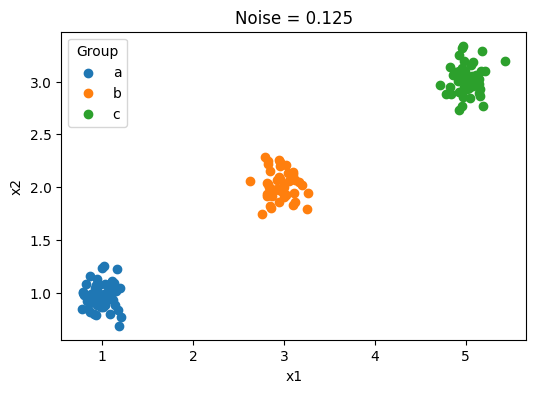

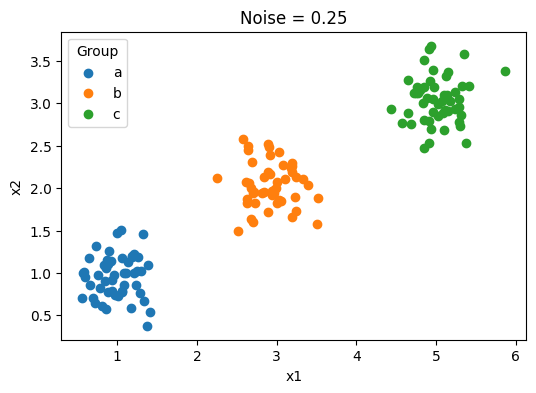

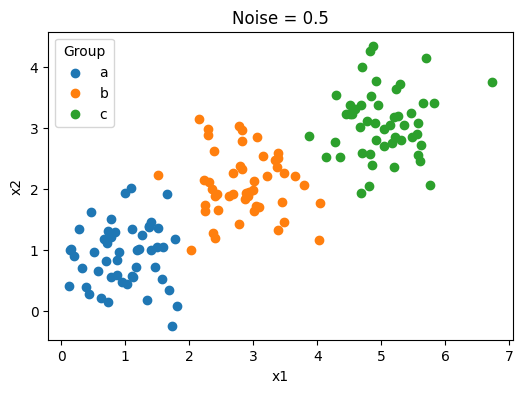

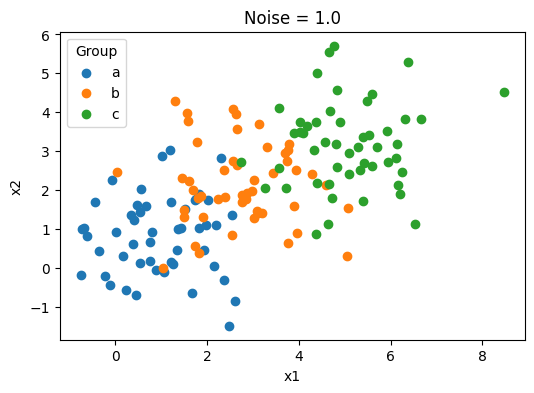

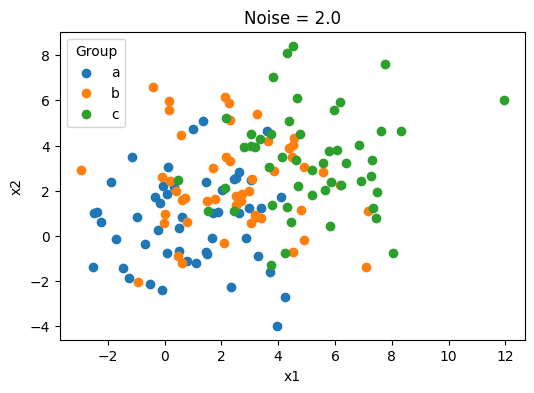

In [8]:
import matplotlib.pyplot as plt

datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

for title, df in datasets.items():

    plt.figure(figsize=(6, 4))

    for group in df['group'].unique():
        subset = df[df['group'] == group]

        plt.scatter(
            subset['x1'],
            subset['x2'],
            label=group
        )

    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.title(title)
    plt.legend(title='Group')
    plt.show()

Q1 - 2. The clusters spread out and begin to overlap more as the noise level rises. The three groups are quite distinct at noise levels of 0.125 and 0.25. The groups are still largely distinguishable at 0.5, but some points become closer together and there is greater dispersion. The clusters, particularly groups a and b, overlap significantly more at 1.0. It is significantly more difficult to visually distinguish the clusters at 2.0 since the groupings are densely jumbled together.

In [9]:
from sklearn.cluster import KMeans

def make_scree(df, title):

    X = df[['x1', 'x2']]

    k_values = range(1, 11)
    inertias = []

    for k in k_values:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        model.fit(X)

        inertias.append(model.inertia_)

    plt.figure(figsize=(6, 4))

    plt.plot(
        k_values,
        inertias,
        marker='o'
    )

    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Inertia')
    plt.title(title)

    plt.xticks(list(k_values))

    plt.show()

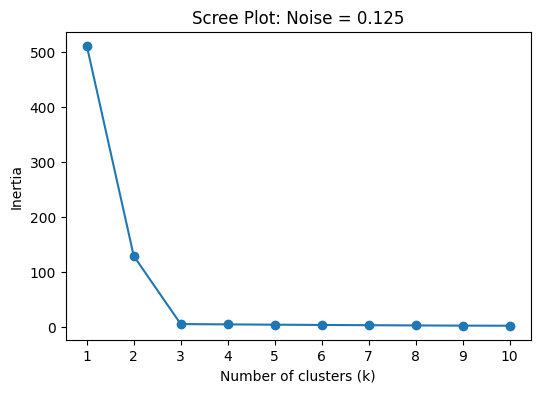

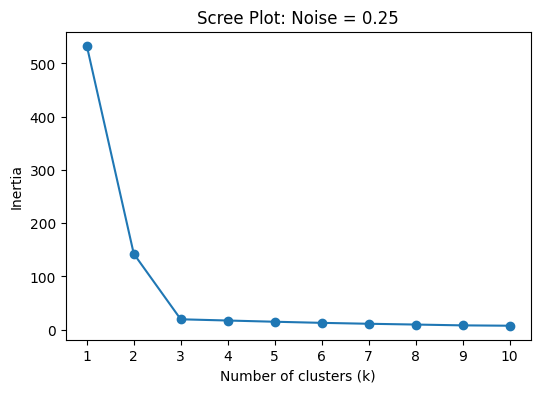

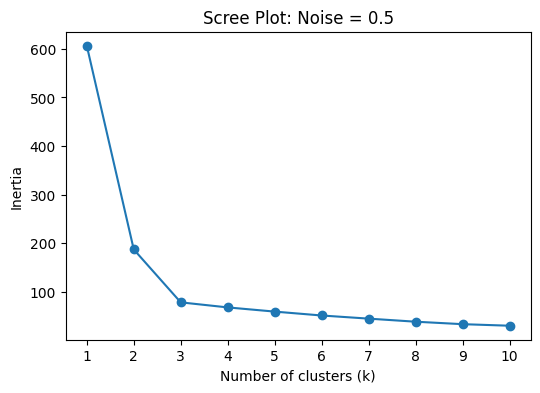

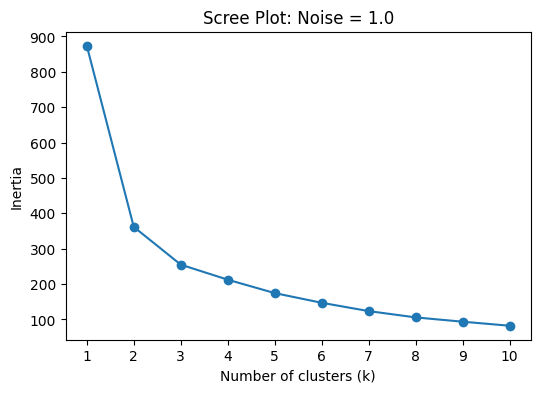

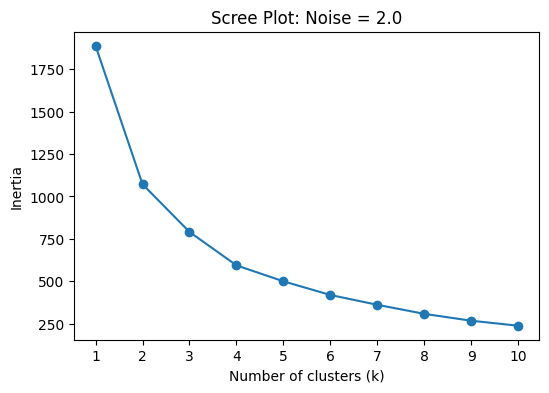

In [10]:
make_scree(df0_125, 'Scree Plot: Noise = 0.125')
make_scree(df0_25, 'Scree Plot: Noise = 0.25')
make_scree(df0_5, 'Scree Plot: Noise = 0.5')
make_scree(df1_0, 'Scree Plot: Noise = 1.0')
make_scree(df2_0, 'Scree Plot: Noise = 2.0')

Q1 - 4. At the lower noise levels, the scree plots' elbow is most pronounced at k = 3, which corresponds to the three groups that produced the data. Moving from one cluster to three clusters results in a significant increase in inertia; after that, the improvement decreases. The elbow is less noticeable as the noise level rises because the groups overlap more. Selecting a value of k from the scree plot with confidence becomes more difficult as a result. The inertia still decreases as k grows at the greatest noise levels, but the point at which the improvement abruptly levels off is not as pronounced.

Q1 - 5. The elbow shows the point at which adding more clusters no longer significantly improves the data's grouping. Moving from k = 1 to k = 2 and then k = 3 significantly minimizes the within-cluster diversity in this simulation because there are three real groups focused in various areas. The algorithm primarily starts splitting groups that already belong together once k exceeds 3, which results in a significantly lower reduction in inertia. The elbow form is produced by this transition from big to modest improvements. The elbow is distinct and the three actual groupings are easy to see when the noise level is low. More noise causes the groups to overlap, making the elbow less noticeable.

In [11]:
import pandas as pd

sipri = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

sipri.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN


In [12]:
sipri.columns.tolist()

['index',
 'Year',
 'Country',
 'Spending (2020 USD)',
 'Percent of GDP',
 'Percent of Government Spending',
 'Spending per Capita']

In [13]:
sipri_2020 = sipri[sipri['Year'] == 2020].copy()
sipri_2020 = sipri_2020.dropna()
print(sipri_2020.shape)

(148, 7)


In [14]:
sipri_2020[
    [
        'Country',
        'Spending (2020 USD)',
        'Spending per Capita',
        'Percent of Government Spending',
        'Percent of GDP'
    ]
].head()

,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
32,Afghanistan,279.576955,7.181899,0.049728,0.013589
66,Albania,187.433234,65.126211,0.037952,0.012583
100,Algeria,9708.277440,221.392384,0.173924,0.066600
134,Angola,993.594405,30.231680,0.074624,0.014442
168,Argentina,2830.929705,62.636731,0.017268,0.007269


In [15]:
sipri_2020[
    [
        'Spending (2020 USD)',
        'Spending per Capita',
        'Percent of Government Spending',
        'Percent of GDP'
    ]
].info()

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 4 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Spending (2020 USD)             148 non-null    float64
 1   Spending per Capita             148 non-null    float64
 2   Percent of Government Spending  148 non-null    float64
 3   Percent of GDP                  148 non-null    float64
dtypes: float64(4)
memory usage: 5.8 KB


In [16]:
sipri_2020.isna().sum()

,0
index,0
Year,0
Country,0
Spending (2020 USD),0
Percent of GDP,0
Percent of Government Spending,0
Spending per Capita,0


Q2 - 1. I ended up with 148 nations after removing rows with missing values and filtering the data to 2020. I didn't need to perform any further cleaning because the four variables I required were already numerical and there were no more missing values.

In [17]:
from sklearn.preprocessing import MinMaxScaler

features_1 = [
    'Spending (2020 USD)',
    'Spending per Capita'
]

scaler1 = MinMaxScaler()

X1 = scaler1.fit_transform(
    sipri_2020[features_1]
)

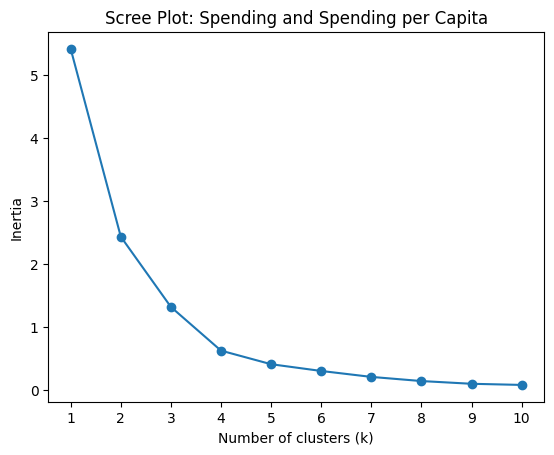

In [18]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias1 = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X1)
    inertias1.append(model.inertia_)

plt.plot(
    range(1, 11),
    inertias1,
    marker='o'
)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.xticks(range(1, 11))
plt.show()

In [19]:
k1 = 4

In [20]:
kmeans1 = KMeans(
    n_clusters=k1,
    random_state=42,
    n_init=10
)

sipri_2020['cluster_spending'] = kmeans1.fit_predict(X1)

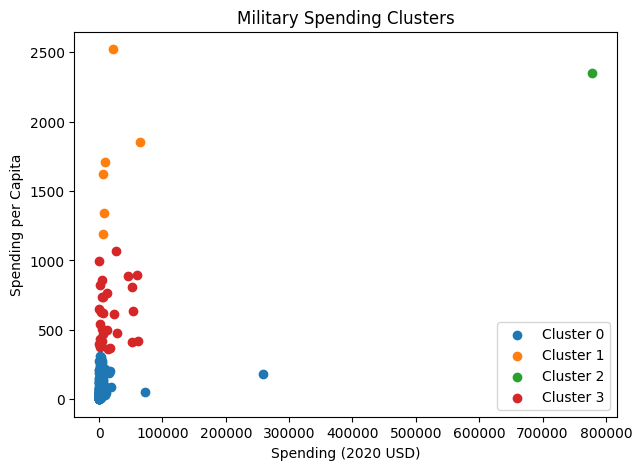

In [21]:
plt.figure(figsize=(7, 5))

for cluster in sorted(sipri_2020['cluster_spending'].unique()):
    subset = sipri_2020[
        sipri_2020['cluster_spending'] == cluster
    ]

    plt.scatter(
        subset['Spending (2020 USD)'],
        subset['Spending per Capita'],
        label=f'Cluster {cluster}'
    )

plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.title('Military Spending Clusters')
plt.legend()
plt.show()

In [22]:
sipri_2020.groupby('cluster_spending')[
    features_1
].describe()

Spending (2020 USD)                               \
                               count           mean           std   
cluster_spending                                                    
0                              111.0    4859.185065  25405.739131   
1                                6.0   19443.362047  22861.507114   
2                                1.0  778397.200000           NaN   
3                               30.0   17077.591354  20583.053357   

                                                                              \
                            min            25%            50%            75%   
cluster_spending                                                               
0                      8.622460     130.010211     382.464677    2297.032353   
1                   6095.708713    7023.251766    8624.225729   18857.070183   
2                 778397.200000  778397.200000  778397.200000  778397.200000   
3                    405.790494    2294.039665    5857.060906   26296.001003   

                                Spending per Capita                           \
                            max               count         mean         std   
cluster_spending                                                               
0                 257973.429834               111.0    80.061470   83.501824   
1                  64558.400000                 6.0  1706.721916  466.375705   
2                 778397.200000                 1.0  2351.631858         NaN   
3                  61712.537169                30.0   607.478618  206.928757   

                                                                      \
                          min          25%          50%          75%   
cluster_spending                                                       
0                    0.580129    14.880549    47.056944   125.387558   
1                 1193.598730  1412.083201  1665.447478  1817.219993   
2                 2351.631858  2351.631858  2351.631858  2351.631858   
3                  362.467076   422.208252   579.004604   757.328513   

                               
                          max  
cluster_spending               
0                  314.201312  
1                 2520.398541  
2                 2351.631858  
3                 1070.623322

In [23]:
sipri_2020[
    sipri_2020['Country'].str.contains(
        'United States',
        case=False,
        na=False
    )
][
    ['Country'] + features_1 + ['cluster_spending']
]

,Country,Spending (2020 USD),Spending per Capita,cluster_spending
5540,United States of America,778397.2,2351.631858,2


Q2 - 2. The scree plot had a noticeable elbow around \(k=4\), so I used four clusters for the k-means model. Most countries were placed in Cluster 0, which had relatively low military spending and spending per capita. Cluster 3 contained countries with somewhat higher values, while Cluster 1 had a small group of countries with much higher spending per capita. The United States was the only country in Cluster 2 because its total military spending was much higher than the rest of the dataset. Overall, the clusters show that most countries are grouped fairly close together, while a few countries stand out because of much higher total spending or spending per person.

The United States is in Cluster 2 by itself. Its total military spending is much higher than every other country in the dataset, which makes it a clear outlier even though several other countries also have high spending per capita.

In [24]:
features_2 = [
    'Percent of Government Spending',
    'Percent of GDP'
]

In [25]:
scaler2 = MinMaxScaler()

X2 = scaler2.fit_transform(
    sipri_2020[features_2]
)

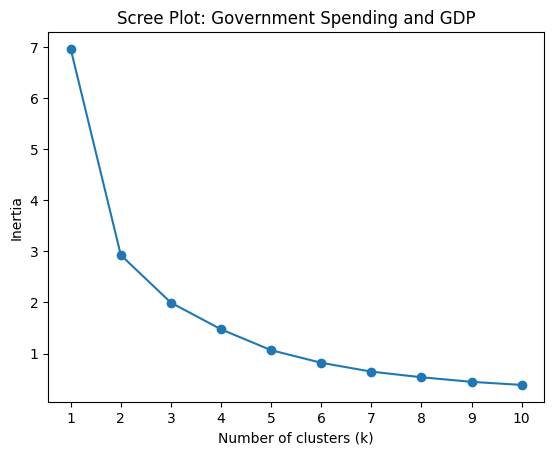

In [26]:
inertias2 = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X2)
    inertias2.append(model.inertia_)

plt.plot(
    range(1, 11),
    inertias2,
    marker='o'
)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Government Spending and GDP')
plt.xticks(range(1, 11))
plt.show()

In [27]:
k2 = 3

In [28]:
kmeans2 = KMeans(
    n_clusters=k2,
    random_state=42,
    n_init=10
)

sipri_2020['cluster_percent'] = kmeans2.fit_predict(X2)

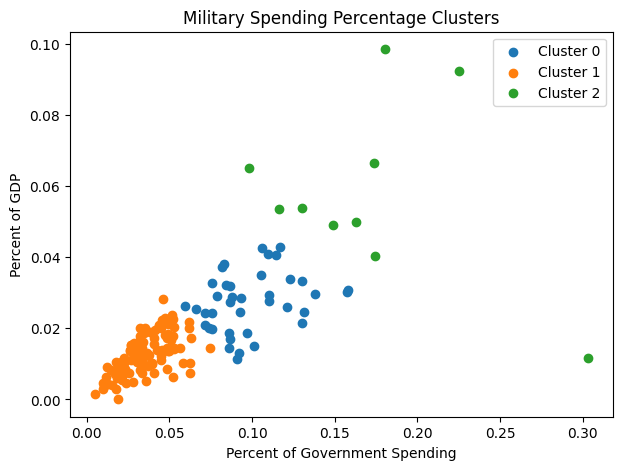

In [29]:
plt.figure(figsize=(7, 5))

for cluster in sorted(sipri_2020['cluster_percent'].unique()):
    subset = sipri_2020[
        sipri_2020['cluster_percent'] == cluster
    ]

    plt.scatter(
        subset['Percent of Government Spending'],
        subset['Percent of GDP'],
        label=f'Cluster {cluster}'
    )

plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.title('Military Spending Percentage Clusters')
plt.legend()
plt.show()

In [30]:
sipri_2020.groupby('cluster_percent')[
    features_2
].describe()

Percent of Government Spending                                \
                                         count      mean       std       min   
cluster_percent                                                                
0                                         39.0  0.098683  0.024125  0.059520   
1                                         99.0  0.035777  0.014549  0.004896   
2                                         10.0  0.171289  0.058725  0.097882   

                                                        Percent of GDP  \
                      25%       50%       75%       max          count   
cluster_percent                                                          
0                0.082430  0.092044  0.112633  0.157918           39.0   
1                0.025921  0.034261  0.047402  0.074624           99.0   
2                0.135010  0.168248  0.179081  0.303027           10.0   

                                                                             \
                     mean       std       min       25%       50%       75%   
cluster_percent                                                               
0                0.027412  0.008191  0.011317  0.021254  0.027781  0.032461   
1                0.012664  0.005681  0.000054  0.008393  0.013191  0.016752   
2                0.058071  0.024867  0.011742  0.049297  0.053729  0.066190   

                           
                      max  
cluster_percent            
0                0.042810  
1                0.028132  
2                0.098470

Q2 - 3. In contrast to Part 2, these clusters are based on the percentage of a nation's GDP and government spending that is allocated to the military rather than the overall amount of money spent. Because a nation may spend a significant portion of its budget or GDP on the military despite having lower overall military spending, this results in a distinct classification. The majority of nations in Cluster 1 had comparatively low percentages, but those in Cluster 2 had significantly larger military spending in relation to their government budgets and economies. Therefore, rather of focusing only on which nations spend the most money overall, our research reveals more about the significance of military spending within each nation.

In [31]:
features_all = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

In [32]:
scaler_all = MinMaxScaler()

X_all = scaler_all.fit_transform(
    sipri_2020[features_all]
)

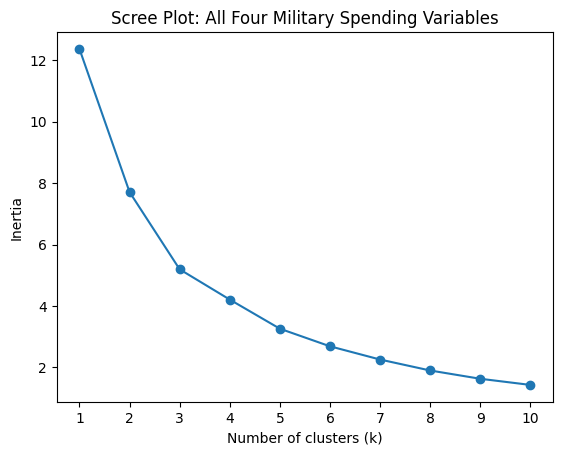

In [34]:
inertias_all = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_all)
    inertias_all.append(model.inertia_)

plt.plot(
    range(1, 11),
    inertias_all,
    marker='o'
)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: All Four Military Spending Variables')
plt.xticks(range(1, 11))
plt.show()

In [35]:
k_all = 3

In [37]:
kmeans_all = KMeans(
    n_clusters=k_all,
    random_state=42,
    n_init=10
)

sipri_2020['cluster_all'] = kmeans_all.fit_predict(X_all)

In [38]:
sipri_2020.groupby('cluster_all')[
    features_all
].describe()

Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                          31.0    8786.086602   17901.909108   162.373364   
1                           6.0  147964.582042  309635.189564  6095.708713   
2                         111.0    7086.472777   26479.379918     8.622460   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             467.787851   1404.787234   7739.166193   72937.064048   
1            7700.424616  15897.570598  53872.942442  778397.200000   
2             130.010211    567.650747   3910.107493  257973.429834   

            Spending per Capita               ...  \
                          count         mean  ...   
cluster_all                                   ...   
0                          31.0   212.689100  ...   
1                           6.0  1875.150751  ...   
2                         111.0   196.926833  ...   

            Percent of Government Spending           Percent of GDP            \
                                       75%       max          count      mean   
cluster_all                                                                     
0                                 0.134663  0.303027           31.0  0.033492   
1                                 0.164503  0.225050            6.0  0.062634   
2                                 0.050505  0.092044          111.0  0.013419   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_all                                                              
0            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
1            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470  
2            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  

[3 rows x 32 columns]

In [39]:
sipri_2020[
    sipri_2020['Country'].str.contains(
        'United States',
        case=False,
        na=False
    )
][
    ['Country'] + features_all + ['cluster_all']
]

,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,cluster_all
5540,United States of America,778397.2,2351.631858,0.081976,0.037179,1


Q2 - 4. When I included all four variables, the clusters included data on the total amount of military spending as well as the size of that spending in relation to each nation's government budget and economy. Compared to the first two sections, this provided a more comprehensive grouping. The majority of nations ended up in Cluster 2, whilst nations with somewhat greater percentage-based military spending were found in Cluster 0. Only six nations made up Cluster 1, which represented nations with exceptionally high spending on a variety of metrics. Instead of being entirely on its own as it was when I merely utilized spending and spending per population, the United States was placed in Cluster 1. This demonstrates how adding the % variables modifies the clusters since the model takes into account more than simply the absolute the amount spent.

Q2 - 5. K-means proved helpful in finding general trends in military spending among nations. While the percentage-based analysis revealed a different pattern depending on how huge military spending is in relation to government budgets and GDP, the clustering made it simpler to distinguish between countries with high absolute spending and those with lower spending. Because it took into account both overall expenditure levels and relative spending, which also altered how some countries were categorized, including all four factors provided a more comprehensive picture. The clusters should be viewed as a means of summarizing patterns rather than as set groupings because the outcomes are dependent on the value of k and may be impacted by extreme countries.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 18f8e43
- **AI tool and model used:** ChatGPT, GPT-5.6 Sol

### *Prompts used

1. Can you review my Phase 1 k-means clustering solution and suggest improvements to the code, scree plot interpretation, clustering choices, and written explanations without completely changing my approach?
2. Can you review my SIPRI military spending clustering analysis and suggest ways to make the normalization, choice of k, cluster interpretation, and comparisons across the different feature sets more robust?

### *AI-proposed changes


1. Make the scree plot interpretation more closely match the actual shape of each curve instead of choosing k too quickly.
2. Make the explanation of increasing noise more specific to what is visible in the scatterplots.
3. Use the normalized variables consistently before running k-means so variables on larger scales do not dominate the clustering.
4. Make the military spending cluster descriptions more specific by using the cluster counts and summary statistics.
5. Compare the absolute-spending clusters, percentage-based clusters, and all-four-variable clusters more directly.
6. Mention the effect of outliers, especially the United States, when interpreting the clusters.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I compared the suggested value of k to the scree plots and used the point where the decrease in inertia started to level off. |
| 2 | Accept | I checked the scatterplots and rewrote the explanation so it matched the amount of overlap actually shown as noise increased. |
| 3 | Accept | I verified that the variables were min-max normalized before clustering so that variables with larger numerical values would not dominate the distance calculation. |
| 4 | Accept | I used the cluster summary tables to make the descriptions match the actual cluster sizes and averages. |
| 5 | Accept | Comparing the three analyses made the differences between absolute and relative military spending clearer. |
| 6 | Accept | The plots and summary tables showed that the United States was an extreme observation in the absolute-spending analysis, so this was important to mention. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])

    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])

    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        'x1': X1[0, :],
        'x2': X1[1, :],
        'group': 'a'
    })

    gdf2 = pd.DataFrame({
        'x1': X2[0, :],
        'x2': X2[1, :],
        'group': 'b'
    })

    gdf3 = pd.DataFrame({
        'x1': X3[0, :],
        'x2': X3[1, :],
        'group': 'c'
    })

    return pd.concat([gdf1, gdf2, gdf3], axis=0)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

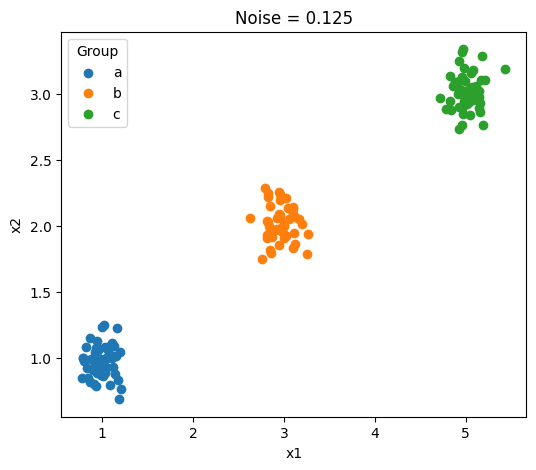

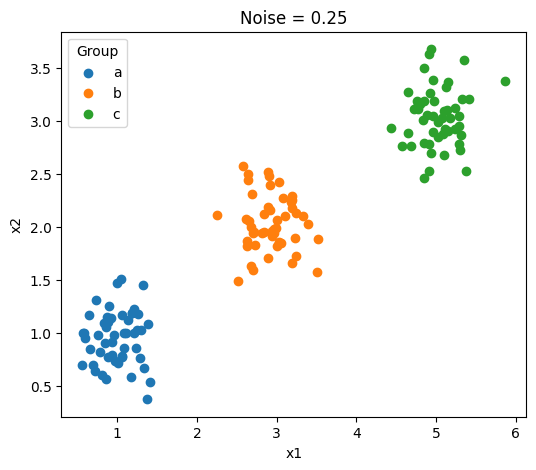

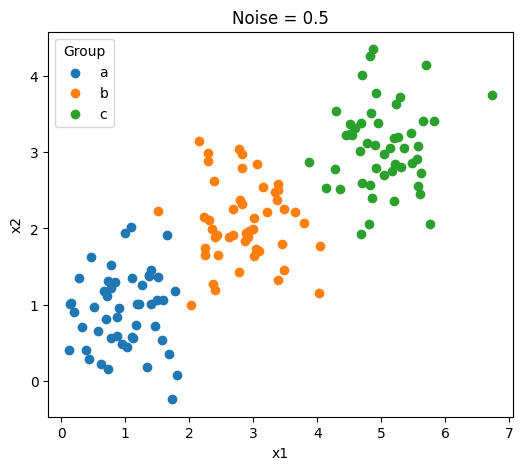

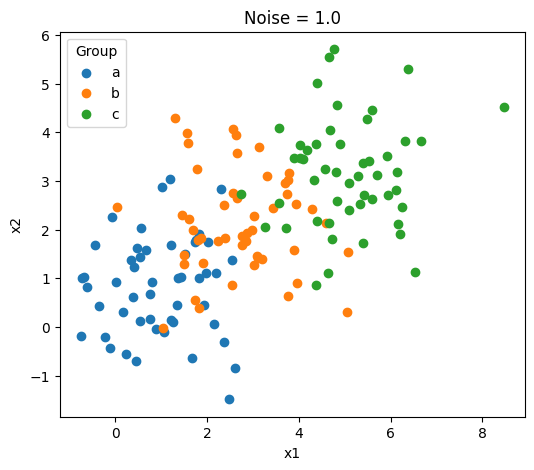

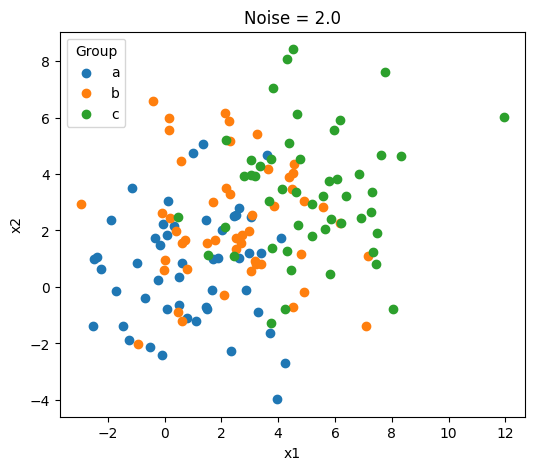

In [41]:
datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

for noise, df in datasets.items():

    plt.figure(figsize=(6, 5))

    for group in df['group'].unique():
        temp = df[df['group'] == group]

        plt.scatter(
            temp['x1'],
            temp['x2'],
            label=group
        )

    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.title(f'Noise = {noise}')
    plt.legend(title='Group')
    plt.show()

Q1 - 2. As the noise increases, the clusters become less visually distinct. At noise levels 0.125 and 0.25, the three groups are tightly packed and clearly separated. At 0.5, the groups are more spread out, but the three general clusters can still be seen. At 1.0, there is much more overlap between the groups. At 2.0, the points overlap heavily, so it becomes difficult to visually separate the three original groups.

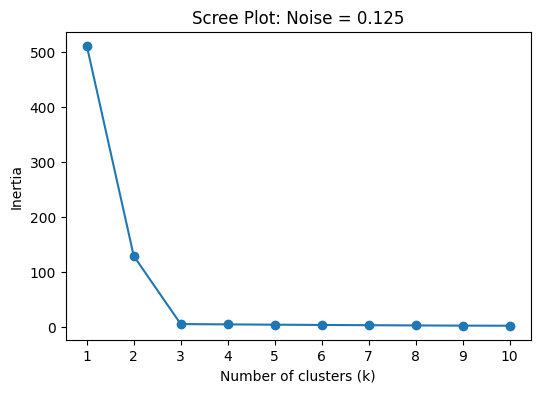

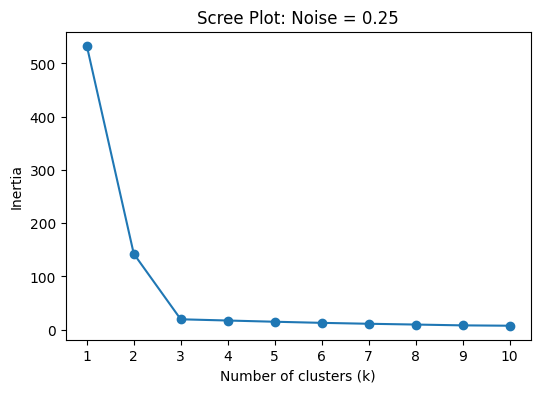

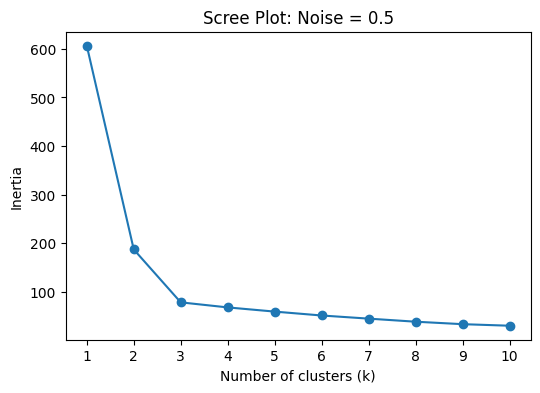

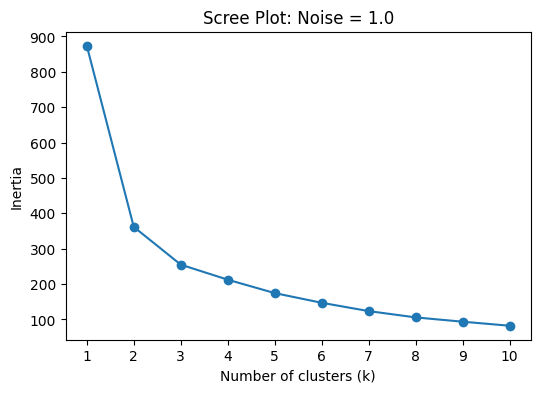

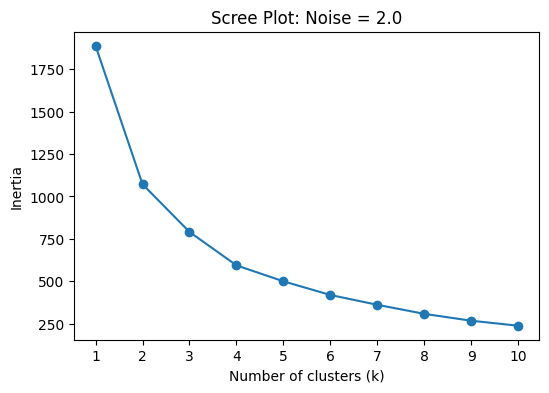

In [43]:
from sklearn.cluster import KMeans

for noise, df in datasets.items():

    X = df[['x1', 'x2']]

    inertias = []

    for k in range(1, 11):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        model.fit(X)
        inertias.append(model.inertia_)

    plt.figure(figsize=(6, 4))

    plt.plot(
        range(1, 11),
        inertias,
        marker='o'
    )

    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Inertia')
    plt.title(f'Scree Plot: Noise = {noise}')
    plt.xticks(range(1, 11))
    plt.show()

Q1 - 3. At the lower noise levels, the scree plots should have a clearer elbow because the three groups are well separated. As the amount of noise increases, the points overlap more and the elbow becomes less obvious. This makes it harder to confidently choose a single value of k. The underlying data were generated from three groups, but at the highest noise levels the clustering structure is much less clear.

Q1 - 4. The elbow represents the point where adding another cluster stops producing a large improvement in the model. Before the elbow, increasing k causes a large decrease in inertia because the model is separating meaningful groups in the data. After the elbow, the decrease becomes much smaller because additional clusters are mostly dividing groups that are already reasonably well represented. In this simulation, the elbow is easier to see when the noise is low because the original three groups are more distinct.

In [44]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = None

for root, dirs, files in os.walk('/content'):
    if 'SIPRI Military Expenditure Database.csv' in files:
        data_path = os.path.join(
            root,
            'SIPRI Military Expenditure Database.csv'
        )
        break

if data_path is None:
    raise FileNotFoundError(
        "SIPRI Military Expenditure Database.csv was not found."
    )

sipri = pd.read_csv(data_path)

sipri_2020 = sipri[
    sipri['Year'] == 2020
].copy()

sipri_2020 = sipri_2020.dropna()

print(sipri_2020.shape)

sipri_2020.head()

(148, 7)


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


In [45]:
features_all = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

print(sipri_2020[features_all].info())
print(sipri_2020[features_all].isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 4 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Spending (2020 USD)             148 non-null    float64
 1   Spending per Capita             148 non-null    float64
 2   Percent of Government Spending  148 non-null    float64
 3   Percent of GDP                  148 non-null    float64
dtypes: float64(4)
memory usage: 5.8 KB
None
Spending (2020 USD)               0
Spending per Capita               0
Percent of Government Spending    0
Percent of GDP                    0
dtype: int64


Q2 - 1. After filtering the data to 2020 and dropping rows with missing values, I ended up with 148 countries. The four variables I needed were already numeric and there were no remaining missing values, so I did not need to do any additional cleaning.

In [46]:
from sklearn.preprocessing import MinMaxScaler

features_1 = [
    'Spending (2020 USD)',
    'Spending per Capita'
]

scaler1 = MinMaxScaler()

X1 = scaler1.fit_transform(
    sipri_2020[features_1]
)

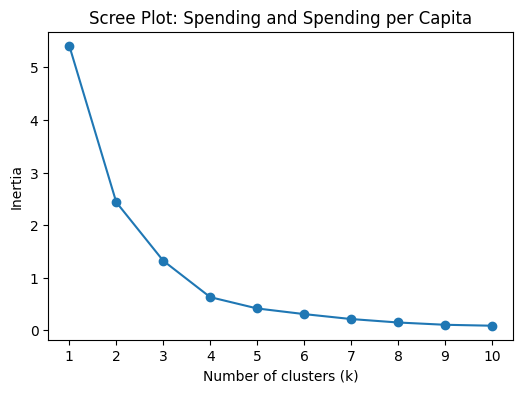

In [47]:
inertias1 = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X1)
    inertias1.append(model.inertia_)

plt.figure(figsize=(6, 4))

plt.plot(
    range(1, 11),
    inertias1,
    marker='o'
)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.xticks(range(1, 11))
plt.show()

In [48]:
k1 = 4

In [49]:
kmeans1 = KMeans(
    n_clusters=k1,
    random_state=42,
    n_init=10
)

sipri_2020['cluster_spending'] = kmeans1.fit_predict(X1)

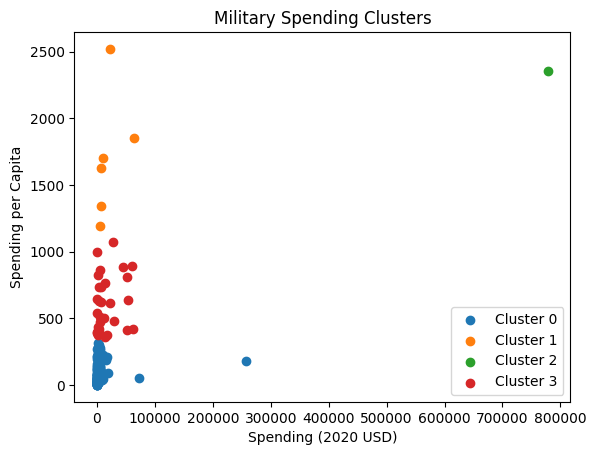

In [50]:
for cluster in sorted(
    sipri_2020['cluster_spending'].unique()
):

    temp = sipri_2020[
        sipri_2020['cluster_spending'] == cluster
    ]

    plt.scatter(
        temp['Spending (2020 USD)'],
        temp['Spending per Capita'],
        label=f'Cluster {cluster}'
    )

plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.title('Military Spending Clusters')
plt.legend()
plt.show()

In [51]:
sipri_2020.groupby(
    'cluster_spending'
)[features_1].describe()

Spending (2020 USD)                               \
                               count           mean           std   
cluster_spending                                                    
0                              111.0    4859.185065  25405.739131   
1                                6.0   19443.362047  22861.507114   
2                                1.0  778397.200000           NaN   
3                               30.0   17077.591354  20583.053357   

                                                                              \
                            min            25%            50%            75%   
cluster_spending                                                               
0                      8.622460     130.010211     382.464677    2297.032353   
1                   6095.708713    7023.251766    8624.225729   18857.070183   
2                 778397.200000  778397.200000  778397.200000  778397.200000   
3                    405.790494    2294.039665    5857.060906   26296.001003   

                                Spending per Capita                           \
                            max               count         mean         std   
cluster_spending                                                               
0                 257973.429834               111.0    80.061470   83.501824   
1                  64558.400000                 6.0  1706.721916  466.375705   
2                 778397.200000                 1.0  2351.631858         NaN   
3                  61712.537169                30.0   607.478618  206.928757   

                                                                      \
                          min          25%          50%          75%   
cluster_spending                                                       
0                    0.580129    14.880549    47.056944   125.387558   
1                 1193.598730  1412.083201  1665.447478  1817.219993   
2                 2351.631858  2351.631858  2351.631858  2351.631858   
3                  362.467076   422.208252   579.004604   757.328513   

                               
                          max  
cluster_spending               
0                  314.201312  
1                 2520.398541  
2                 2351.631858  
3                 1070.623322

In [52]:
sipri_2020[
    sipri_2020['Country'].str.contains(
        'United States',
        case=False,
        na=False
    )
][
    ['Country'] +
    features_1 +
    ['cluster_spending']
]

,Country,Spending (2020 USD),Spending per Capita,cluster_spending
5540,United States of America,778397.2,2351.631858,2


Q2 - 2. The scree plot had a noticeable elbow around \(k=4\), so I used four clusters. Most countries were placed in Cluster 0, which had relatively low total spending and spending per capita. Cluster 3 included countries with moderately higher values, while Cluster 1 contained a small number of countries with especially high spending per person. The United States was the only country in Cluster 2 because its total military spending was much larger than the rest of the dataset. This shows that the United States is a major outlier when looking at absolute military spending.

In [53]:
features_2 = [
    'Percent of Government Spending',
    'Percent of GDP'
]

scaler2 = MinMaxScaler()

X2 = scaler2.fit_transform(
    sipri_2020[features_2]
)

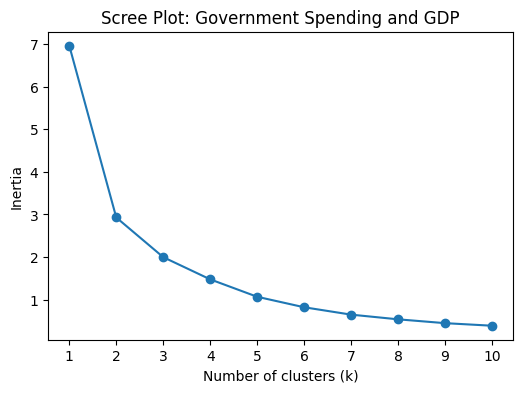

In [54]:
inertias2 = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X2)
    inertias2.append(model.inertia_)

plt.figure(figsize=(6, 4))

plt.plot(
    range(1, 11),
    inertias2,
    marker='o'
)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: Government Spending and GDP')
plt.xticks(range(1, 11))
plt.show()

In [55]:
k2 = 3

In [57]:
kmeans2 = KMeans(
    n_clusters=k2,
    random_state=42,
    n_init=10
)

sipri_2020['cluster_percent'] = kmeans2.fit_predict(X2)

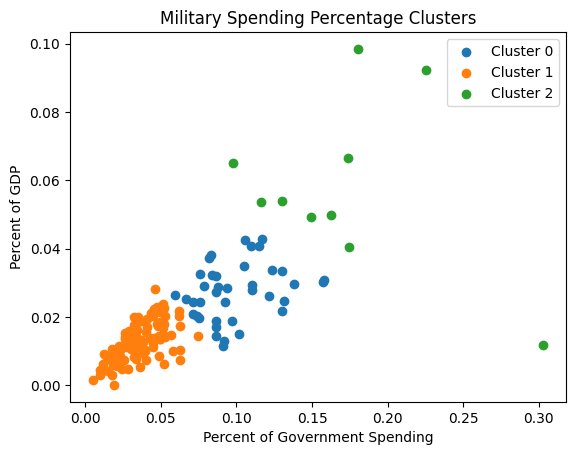

In [58]:
for cluster in sorted(
    sipri_2020['cluster_percent'].unique()
):

    temp = sipri_2020[
        sipri_2020['cluster_percent'] == cluster
    ]

    plt.scatter(
        temp['Percent of Government Spending'],
        temp['Percent of GDP'],
        label=f'Cluster {cluster}'
    )

plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.title('Military Spending Percentage Clusters')
plt.legend()
plt.show()

In [59]:
sipri_2020.groupby(
    'cluster_percent'
)[features_2].describe()

Percent of Government Spending                                \
                                         count      mean       std       min   
cluster_percent                                                                
0                                         39.0  0.098683  0.024125  0.059520   
1                                         99.0  0.035777  0.014549  0.004896   
2                                         10.0  0.171289  0.058725  0.097882   

                                                        Percent of GDP  \
                      25%       50%       75%       max          count   
cluster_percent                                                          
0                0.082430  0.092044  0.112633  0.157918           39.0   
1                0.025921  0.034261  0.047402  0.074624           99.0   
2                0.135010  0.168248  0.179081  0.303027           10.0   

                                                                             \
                     mean       std       min       25%       50%       75%   
cluster_percent                                                               
0                0.027412  0.008191  0.011317  0.021254  0.027781  0.032461   
1                0.012664  0.005681  0.000054  0.008393  0.013191  0.016752   
2                0.058071  0.024867  0.011742  0.049297  0.053729  0.066190   

                           
                      max  
cluster_percent            
0                0.042810  
1                0.028132  
2                0.098470

Q2 - 3. This analysis produced a different pattern from Part 2 because it focuses on how large military spending is relative to each country's economy and government budget instead of the total amount of money spent. Most countries were in Cluster 1 and had relatively low percentages. Cluster 0 had moderately higher percentages, while Cluster 2 contained a smaller number of countries that devoted much larger shares of their GDP or government spending to the military. This shows that countries with the highest total military spending are not necessarily the same countries that devote the largest share of their resources to the military.

In [60]:
features_all = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

scaler_all = MinMaxScaler()

X_all = scaler_all.fit_transform(
    sipri_2020[features_all]
)

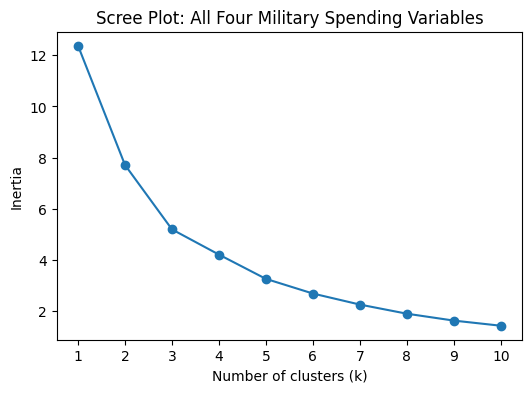

In [61]:
inertias_all = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_all)
    inertias_all.append(model.inertia_)

plt.figure(figsize=(6, 4))

plt.plot(
    range(1, 11),
    inertias_all,
    marker='o'
)

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Scree Plot: All Four Military Spending Variables')
plt.xticks(range(1, 11))
plt.show()

In [62]:
k_all = 3

In [63]:
kmeans_all = KMeans(
    n_clusters=k_all,
    random_state=42,
    n_init=10
)

sipri_2020['cluster_all'] = kmeans_all.fit_predict(X_all)

In [64]:
sipri_2020.groupby(
    'cluster_all'
)[features_all].describe()

Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                          31.0    8786.086602   17901.909108   162.373364   
1                           6.0  147964.582042  309635.189564  6095.708713   
2                         111.0    7086.472777   26479.379918     8.622460   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             467.787851   1404.787234   7739.166193   72937.064048   
1            7700.424616  15897.570598  53872.942442  778397.200000   
2             130.010211    567.650747   3910.107493  257973.429834   

            Spending per Capita               ...  \
                          count         mean  ...   
cluster_all                                   ...   
0                          31.0   212.689100  ...   
1                           6.0  1875.150751  ...   
2                         111.0   196.926833  ...   

            Percent of Government Spending           Percent of GDP            \
                                       75%       max          count      mean   
cluster_all                                                                     
0                                 0.134663  0.303027           31.0  0.033492   
1                                 0.164503  0.225050            6.0  0.062634   
2                                 0.050505  0.092044          111.0  0.013419   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_all                                                              
0            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
1            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470  
2            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  

[3 rows x 32 columns]

In [65]:
sipri_2020[
    sipri_2020['Country'].str.contains(
        'United States',
        case=False,
        na=False
    )
][
    ['Country'] +
    features_all +
    ['cluster_all']
]

,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,cluster_all
5540,United States of America,778397.2,2351.631858,0.081976,0.037179,1


Q2 - 4. When I used all four variables together, the clusters combined both absolute military spending and spending relative to each country's economy and government budget. Most countries were placed in Cluster 2, while Cluster 0 included countries with somewhat higher values across the percentage measures. Cluster 1 contained only six countries and represented countries with especially high values across several military spending measures. The United States was placed in Cluster 1 instead of being completely by itself like it was in the two-variable spending analysis. This shows that adding the percentage variables changes how the countries are grouped and gives a broader view of military spending patterns.

Q2 - 5. K-means was useful for identifying broad patterns in military spending across countries. The clustering made it easier to separate countries with high absolute spending from countries with lower spending, while the percentage-based analysis showed a different pattern based on how large military spending is relative to government budgets and GDP. Using all four variables gave a more complete view because it considered both overall spending levels and relative spending, which also changed how some countries were grouped. At the same time, the results depend on the value of k and can be affected by extreme countries, so the clusters should be treated as a way to summarize patterns rather than as fixed categories.

In [66]:
print("Number of countries:", len(sipri_2020))

print("\nMissing values:")
print(sipri_2020[features_all].isna().sum())

print("\nSpending clusters:")
print(sipri_2020['cluster_spending'].value_counts().sort_index())

print("\nPercentage clusters:")
print(sipri_2020['cluster_percent'].value_counts().sort_index())

print("\nAll-variable clusters:")
print(sipri_2020['cluster_all'].value_counts().sort_index())

print("\nUnited States:")
print(
    sipri_2020[
        sipri_2020['Country'].str.contains(
            'United States',
            case=False,
            na=False
        )
    ][
        ['Country',
         'cluster_spending',
         'cluster_percent',
         'cluster_all']
    ]
)

Number of countries: 148

Missing values:
Spending (2020 USD)               0
Spending per Capita               0
Percent of Government Spending    0
Percent of GDP                    0
dtype: int64

Spending clusters:
cluster_spending
0    111
1      6
2      1
3     30
Name: count, dtype: int64

Percentage clusters:
cluster_percent
0    39
1    99
2    10
Name: count, dtype: int64

All-variable clusters:
cluster_all
0     31
1      6
2    111
Name: count, dtype: int64

United States:
                       Country  cluster_spending  cluster_percent  cluster_all
5540  United States of America                 2                0            1


### *Reflection on AI assistance
In your own words without generative AI.

Making my explanations and clustering decisions more in line with the actual data was the largest improvement I made in Phase 2. I modified some of the interpretations of the scree plots, focused the discussion of noise on what the plots revealed, and used the summary tables rather than just the graphs to describe the SIPRI clusters. Since k-means is based on distance and I wanted to ensure that the larger-scale factors did not control the grouping, I also maintained the min-max normalization. The fact that some recommendations still needed to be verified against the real plots was one drawback of the AI assistance. For instance, I didn't want to accept a value of k without first examining the scree plot. I checked the number of countries, missing values, cluster sizes, summary statistics, and the United States' position in each study to confirm the updated solution. One unresolved issue is that outliers, particularly those nations with exceptionally high military spending, can have an impact on k-means. In my opinion, the clusters are best suited for illustrating broad trends rather than establishing precise classifications because the outcomes also rely on the value of k.